In [1]:
# ============================================================
# 1. Environment Verification and Data Paths
# ============================================================

from pathlib import Path
import sys
import subprocess

import numpy as np
import pandas as pd
from PIL import Image
from importlib.metadata import version

# Project directory
PROJECT_ROOT = Path.cwd().resolve()
DEMO_DIR = PROJECT_ROOT / "Demo_data"

# PLINK2 executable in the active environment
PLINK2 = Path(sys.prefix) / "bin" / "plink2"

# ------------------------------------------------------------
# Software environment
# ------------------------------------------------------------

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Pillow:", version("Pillow"))

if not PLINK2.is_file():
    raise FileNotFoundError(
        "PLINK2 was not found in the active environment. "
        "Please select the T2D Main kernel."
    )

result = subprocess.run(
    [str(PLINK2), "--version"],
    capture_output=True,
    text=True,
    check=True
)

print("PLINK2:", result.stdout.strip())

# ------------------------------------------------------------
# Demo dataset
# ------------------------------------------------------------

if not DEMO_DIR.is_dir():
    raise FileNotFoundError(
        f"Demo dataset not found: {DEMO_DIR}"
    )

print("\nDemo dataset:", DEMO_DIR)
print("\nEnvironment and data paths verified.")


Python: 3.11.18
NumPy: 1.26.4
pandas: 2.2.3
Pillow: 11.3.0
PLINK2: PLINK v2.0.0-a.7.13 64-bit (15 Oct 2026)

Demo dataset: [LOCAL_PATH]

Environment and data paths verified.


In [3]:
# ============================================================
# 2. Demo Dataset Summary
# ============================================================

import tempfile
import matplotlib.pyplot as plt

# Load sample information
sample_info = pd.read_csv(
    DEMO_DIR / "1-1.Sample_information/sample_information.csv"
)

# Dataset partitions
split_col = next(
    (c for c in sample_info.columns
     if c.lower() in ["split", "dataset", "partition", "data_split", "group", "set"]),
    None
)

print("Total samples:", len(sample_info))

if split_col:
    print("\nDataset partitions:")
    print(sample_info[split_col].value_counts().to_string())

# Image counts
modalities = ["ABD", "BMD_left_hip", "BMD_right_hip", "BMD_spine"]
image_root = DEMO_DIR / "1-2.Sample_image"

summary = pd.DataFrame({
    "Demo_ID": sample_info["Demo_ID"].astype(str)
})

if split_col:
    summary["Dataset"] = sample_info[split_col]

for modality in modalities:
    summary[f"N_{modality}"] = [
        len(list((image_root / modality).glob(f"{sid}_{modality}_*.jpg")))
        for sid in summary["Demo_ID"]
    ]

# Genotype availability
geno_prefix = DEMO_DIR / "1-3.Sample_genotype/demo_chr22"

fam = pd.read_csv(
    str(geno_prefix) + ".fam",
    sep=r"\s+", header=None, dtype={0: str, 1: str}
)

geno_ids = set(fam[1])
summary["Has_Genotype"] = summary["Demo_ID"].isin(geno_ids)

# Missing values in sample information
summary["Missing_Values"] = sample_info.isna().sum(axis=1)

# Genotype missingness (temporary output only)
with tempfile.TemporaryDirectory() as tmp:
    prefix = Path(tmp) / "genotype_missing"

    subprocess.run(
        [str(PLINK2), "--bfile", str(geno_prefix),
         "--missing", "--out", str(prefix)],
        check=True, capture_output=True, text=True
    )

    smiss = pd.read_csv(str(prefix) + ".smiss", sep=r"\s+")
    smiss.columns = smiss.columns.str.lstrip("#")

    missing_rate = smiss.set_index("IID")["F_MISS"]
    summary["Genotype_Missing_Rate"] = (
        summary["Demo_ID"].map(missing_rate).fillna(0)
    )

print("\nImage counts:")
print(summary[[f"N_{m}" for m in modalities]].sum().to_string())

print("\nGenotype available:", summary["Has_Genotype"].sum())
print("Samples with missing information:", (summary["Missing_Values"] > 0).sum())
print("Samples with missing genotype calls:",
      (summary["Genotype_Missing_Rate"] > 0).sum())

print("\nPer-sample summary:")
display(summary)


Total samples: 100

Dataset partitions:
Dataset
training2     32
training1     32
testing       20
validation    16

Image counts:
N_ABD              2487
N_BMD_left_hip      100
N_BMD_right_hip     100
N_BMD_spine         100

Genotype available: 100
Samples with missing information: 0
Samples with missing genotype calls: 0

Per-sample summary:


,Demo_ID,Dataset,N_ABD,N_BMD_left_hip,N_BMD_right_hip,N_BMD_spine,Has_Genotype,Missing_Values,Genotype_Missing_Rate
0,D001,training2,21,1,1,1,True,0,0
1,D002,testing,27,1,1,1,True,0,0
2,D003,training2,23,1,1,1,True,0,0
3,D004,training1,23,1,1,1,True,0,0
4,D005,training2,24,1,1,1,True,0,0
...,...,...,...,...,...,...,...,...,...
95,D096,testing,24,1,1,1,True,0,0
96,D097,training1,25,1,1,1,True,0,0
97,D098,validation,31,1,1,1,True,0,0
98,D099,testing,22,1,1,1,True,0,0


Participant: D001

ABD: 21 images


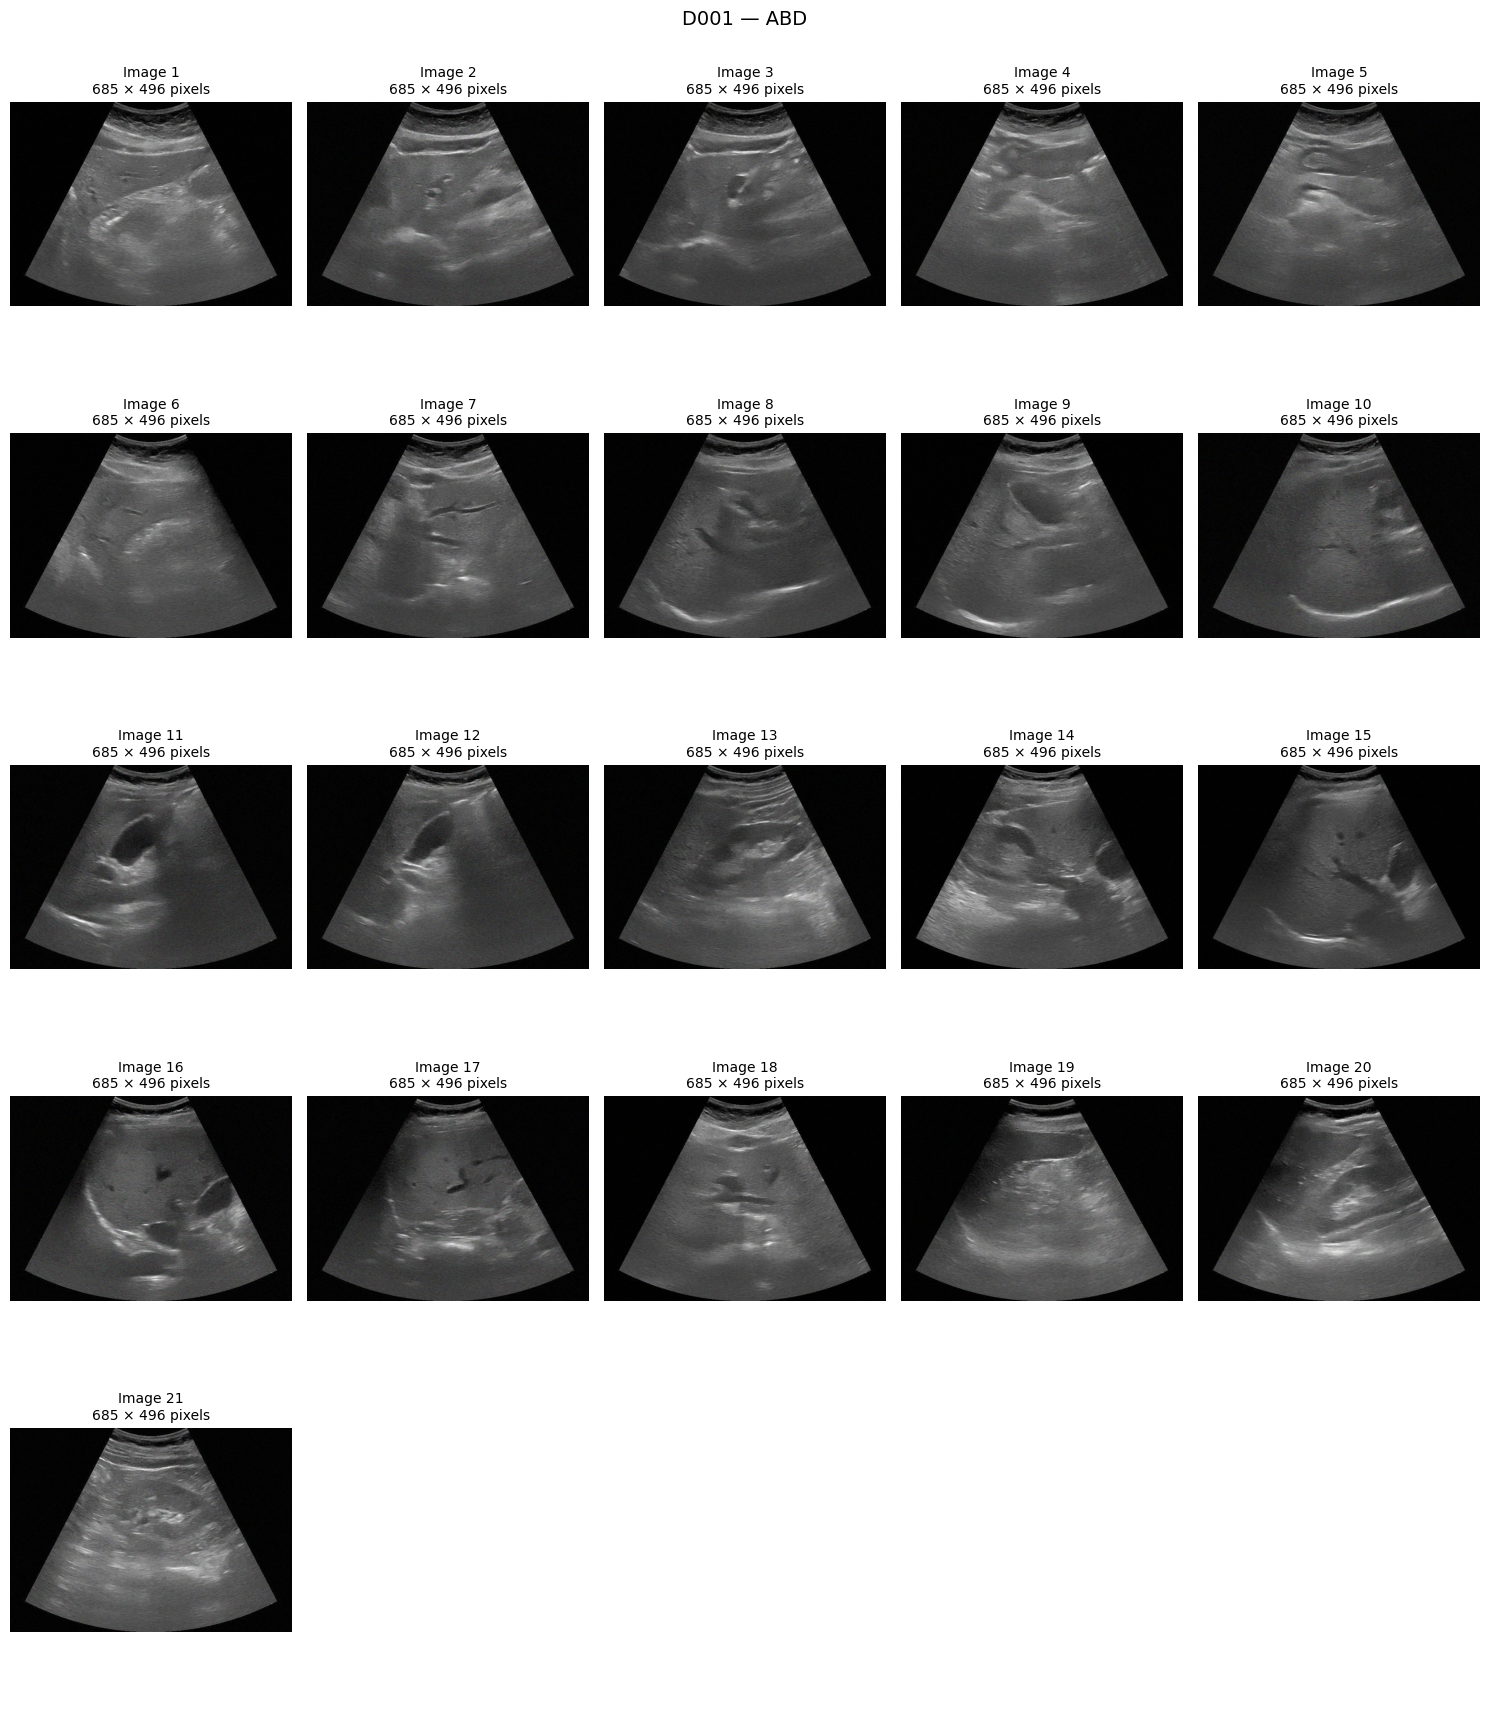


BMD_left_hip: 1 images


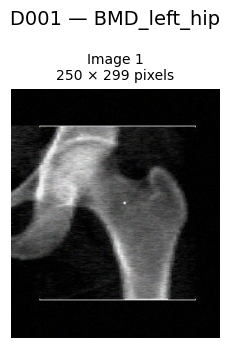


BMD_right_hip: 1 images


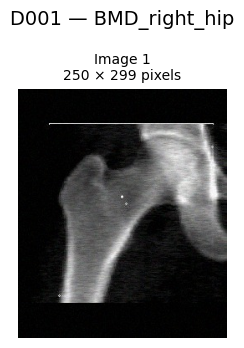


BMD_spine: 1 images


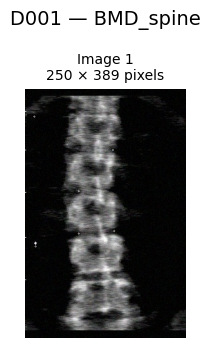

In [6]:
# ============================================================
# 3. Medical Image Preview by Demo_ID
# ============================================================

import math

# Select a participant
DEMO_ID = "D001"  # Change to D002, D003, ..., D100

if DEMO_ID not in sample_info["Demo_ID"].astype(str).values:
    raise ValueError(f"Demo_ID not found: {DEMO_ID}")

modalities = [
    "ABD",
    "BMD_left_hip",
    "BMD_right_hip",
    "BMD_spine"
]

image_root = DEMO_DIR / "1-2.Sample_image"

print(f"Participant: {DEMO_ID}")
print("=" * 60)

for modality in modalities:

    image_files = sorted(
        (image_root / modality).glob(
            f"{DEMO_ID}_{modality}_*.jpg"
        )
    )

    n_images = len(image_files)

    print(f"\n{modality}: {n_images} images")

    if n_images == 0:
        continue

    # Display all images, up to 5 per row
    n_cols = min(5, n_images)
    n_rows = math.ceil(n_images / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3 * n_cols, 3.5 * n_rows),
        squeeze=False
    )

    axes = axes.flatten()

    for i, image_file in enumerate(image_files):

        with Image.open(image_file) as img:
            width, height = img.size
            axes[i].imshow(img.convert("RGB"))

        axes[i].set_title(
            f"Image {i+1}\n{width} × {height} pixels",
            fontsize=10
        )
        axes[i].axis("off")

    # Hide unused subplots
    for i in range(n_images, len(axes)):
        axes[i].axis("off")

    fig.suptitle(
        f"{DEMO_ID} — {modality}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()